# Predição de Inadimplência e Recuperabilidade Tributária — Palmas/TO (Sprint 4 - E3)

**Projeto Integrador:** Inteligência Tributária (SEFIN Palmas)  
**Objetivo:** Consolidar a trilha completa de Ciência de Dados de forma reprodutível (`EDA → Pré-processamento → Split Temporal → Baselines → Modelagem Avançada → Avaliação → Serialização`) e versionar os artefatos em `models/`.

### Conformidade e Governança
- **RNF01 (IPTU Social):** Exclusão de 100% dos beneficiários de isenção social antes da modelagem (`src/ml/preparar_base.py`).
- **LGPD (Art. 20 e Art. 37):** Remoção de identificadores pessoais diretos (`cpf_cnpj`, `nome`, `contato`, `logradouro`, `inscricao_imobiliaria`).
- **Prevenção de Vazamento Temporal (*Data Leakage*):** Divisão cronológica estrita (`60% / 20% / 20%`) via `src/ml/divisao_temporal.py`, com ajuste de transformadores exclusivamente no conjunto de treino.

## 1. Configuração do Ambiente e Reprodutibilidade

In [1]:
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.ml.preparar_base import preparar_base
from src.ml.divisao_temporal import dividir_temporal
from src.ml.scoring_recuperabilidade import (
    ATRIBUTOS_NUMERICOS,
    ATRIBUTOS_CATEGORICOS,
    gerar_scoring_recuperabilidade,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='deep')

PASTA_MODELS = RAIZ / 'models'
PASTA_MODELS.mkdir(parents=True, exist_ok=True)
print(f'Diretório raiz configurado: {RAIZ}')

Diretório raiz configurado: /workspaces/inteligencia_tributaria


## 2. Ingestão de Dados, Filtro RNF01 (IPTU Social) e Histórico Temporal

Carrega `data/tratado/historico_temporal_sintetico.csv`. Se o ambiente for um clone limpo sem os arquivos locais em `data/`, a célula reconstrói de forma determinística (`seed=42`) a base longitudinal de 12 meses aplicando `preparar_base()`.

In [2]:
caminho_bruto = RAIZ / 'data' / 'bruto' / 'carteira_contribuintes_sintetica.csv'
caminho_historico = RAIZ / 'data' / 'tratado' / 'historico_temporal_sintetico.csv'

def construir_carteira_fallback(n_contribuintes: int = 5000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    is_social = rng.random(n_contribuintes) < 0.12
    tipo_imovel = rng.choice(['residencial', 'comercial', 'terreno'], size=n_contribuintes, p=[0.65, 0.22, 0.13])
    setor_urbano = rng.choice(['SU-01', 'SU-02', 'SU-03', 'SU-04'], size=n_contribuintes, p=[0.30, 0.35, 0.20, 0.15])
    area = np.round(rng.lognormal(mean=4.7, sigma=0.55, size=n_contribuintes), 2)
    valor_venal = np.round(area * rng.uniform(1200, 3800, size=n_contribuintes), 2)
    valor_iptu = np.round(valor_venal * np.where(tipo_imovel == 'terreno', 0.015, 0.008), 2)
    exercicios_inad = rng.poisson(lam=1.1, size=n_contribuintes).clip(0, 5)
    parcelamento_rompido = (rng.random(n_contribuintes) < (0.08 + 0.07 * exercicios_inad)).astype(int)
    divida = np.round(valor_iptu * exercicios_inad * rng.uniform(0.6, 1.4, size=n_contribuintes), 2)

    return pd.DataFrame({
        'cpf_cnpj': [f'{i:011d}' for i in range(n_contribuintes)],
        'nome': [f'Contribuinte {i}' for i in range(n_contribuintes)],
        'contato': [f'user{i}@exemplo.com' for i in range(n_contribuintes)],
        'logradouro': [f'Quadra {i % 100}, Lote {i % 30}' for i in range(n_contribuintes)],
        'inscricao_imobiliaria': [f'0001-{i:04d}-001' for i in range(n_contribuintes)],
        'is_iptu_social': is_social,
        'area_construida_m2': area,
        'valor_venal': valor_venal,
        'valor_iptu_anual': valor_iptu,
        'distancia_centro_km': np.round(rng.uniform(0.5, 18.0, size=n_contribuintes), 2),
        'exercicios_inadimplentes_5a': exercicios_inad,
        'tempo_inadimplencia_dias': exercicios_inad * rng.integers(30, 180, size=n_contribuintes),
        'valor_divida_consolidada': divida,
        'qtd_parcelamentos_anteriores': rng.poisson(lam=0.6, size=n_contribuintes),
        'parcelamento_rompido': parcelamento_rompido,
        'qtd_notificacoes': rng.poisson(lam=1.2, size=n_contribuintes),
        'tipo_imovel': tipo_imovel,
        'setor_urbano': setor_urbano,
    })

if caminho_historico.is_file():
    df_historico = pd.read_csv(
        caminho_historico,
        parse_dates=['data_referencia_simulada', 'data_disponibilidade_alvo']
    )
    print(f'Histórico carregado de disco: {caminho_historico} ({len(df_historico):,} registros)')
else:
    print('Aviso: historico_temporal_sintetico.csv não encontrado. Gerando base reprodutível...')
    df_bruto = pd.read_csv(caminho_bruto, sep=';') if caminho_bruto.is_file() else construir_carteira_fallback()
    estado = preparar_base(df_bruto).drop(
        columns=['inadimplente_proximo_exercicio', 'divida_recuperada_12m'], errors='ignore'
    ).reset_index(drop=True)

    rng = np.random.default_rng(RANDOM_STATE)
    periodos = pd.date_range('2024-01-01', periods=12, freq='MS')
    historico = []
    for numero, data in enumerate(periodos):
        obs = estado.copy()
        logit = (
            -1.7
            + 0.25 * estado['exercicios_inadimplentes_5a']
            + 0.40 * estado['parcelamento_rompido']
            + 0.14 * np.log1p(estado['valor_divida_consolidada'] / 1000)
            + 0.20 * (estado['tipo_imovel'] == 'terreno')
            + 0.12 * np.sin(2 * np.pi * numero / 12)
        )
        prob = 1 / (1 + np.exp(-logit))
        resultado = rng.binomial(1, prob.to_numpy())
        obs['data_referencia_simulada'] = data
        obs['data_disponibilidade_alvo'] = data + pd.offsets.MonthBegin(1)
        obs['inadimplente_proximo_periodo'] = resultado
        historico.append(obs)

        estado['tempo_inadimplencia_dias'] = np.where(
            resultado == 1,
            estado['tempo_inadimplencia_dias'] + 30,
            np.maximum(estado['tempo_inadimplencia_dias'] - 30, 0)
        )
        estado['valor_divida_consolidada'] = np.maximum(
            0,
            estado['valor_divida_consolidada'].to_numpy()
            + resultado * estado['valor_iptu_anual'].to_numpy() / 12
            - (1 - resultado) * estado['valor_iptu_anual'].to_numpy() / 24
        ).round(2)
        estado['qtd_notificacoes'] += ((resultado == 1) & (rng.random(len(estado)) < 0.20)).astype(int)

    df_historico = pd.concat(historico, ignore_index=True)
    caminho_historico.parent.mkdir(parents=True, exist_ok=True)
    df_historico.to_csv(caminho_historico, index=False)
    print(f'Histórico gerado e salvo em: {caminho_historico} ({len(df_historico):,} registros)')

colunas_proibidas = {'cpf_cnpj', 'nome', 'contato', 'logradouro', 'inscricao_imobiliaria', 'is_iptu_social'}
assert colunas_proibidas.isdisjoint(df_historico.columns), 'Violação de privacidade/RNF01 detectada!'
df_historico.head(3)

Histórico carregado de disco: /workspaces/inteligencia_tributaria/data/tratado/historico_temporal_sintetico.csv (223,284 registros)


,id_contribuinte,setor_urbano,faixa_renda_setor,tipo_imovel,area_construida_m2,valor_venal,valor_iptu_anual,distancia_centro_km,exercicios_inadimplentes_5a,tempo_inadimplencia_dias,valor_divida_consolidada,qtd_parcelamentos_anteriores,parcelamento_rompido,qtd_notificacoes,data_referencia_simulada,data_disponibilidade_alvo,inadimplente_proximo_periodo
0,b5ba48db3af13ea4,Taquari,baixa,comercial,108.4,134131.89,859.48,14.18,4,1379,4769.35,0,0,1,2024-01-01,2024-02-01,1
1,b357eb268ab315e6,Taquaralto,baixa,industrial,18.4,398426.95,2404.12,14.75,3,914,9350.06,0,0,4,2024-01-01,2024-02-01,0
2,e2c9e002c0a4b612,Setor Comercial Central,alta,residencial,257.9,557395.83,3467.45,2.76,0,0,0.00,0,0,0,2024-01-01,2024-02-01,1


## 3. Análise Exploratória de Dados (EDA)

Dimensões da base: 223,284 linhas x 17 colunas
Valores ausentes totais: 0
Taxa global de inadimplência (classe 1): 26.60%


,min,25%,50%,mean,75%,max
area_construida_m2,0.00,61.20,96.90,114.50,148.20,1346.20
valor_venal,15500.82,130220.96,218289.25,293468.85,366373.85,4510779.55
valor_iptu_anual,73.06,751.78,1291.57,1757.35,2191.59,29317.60
distancia_centro_km,0.00,5.03,8.78,8.82,12.57,25.14
exercicios_inadimplentes_5a,0.00,1.00,2.00,1.65,2.00,5.00
tempo_inadimplencia_dias,0.00,135.00,523.00,682.41,1011.00,6859.00
valor_divida_consolidada,0.00,769.70,2096.63,3359.69,4355.84,96486.59
qtd_parcelamentos_anteriores,0.00,0.00,0.00,0.45,1.00,5.00
parcelamento_rompido,0.00,0.00,0.00,0.15,0.00,1.00
qtd_notificacoes,0.00,1.00,2.00,2.04,3.00,12.00


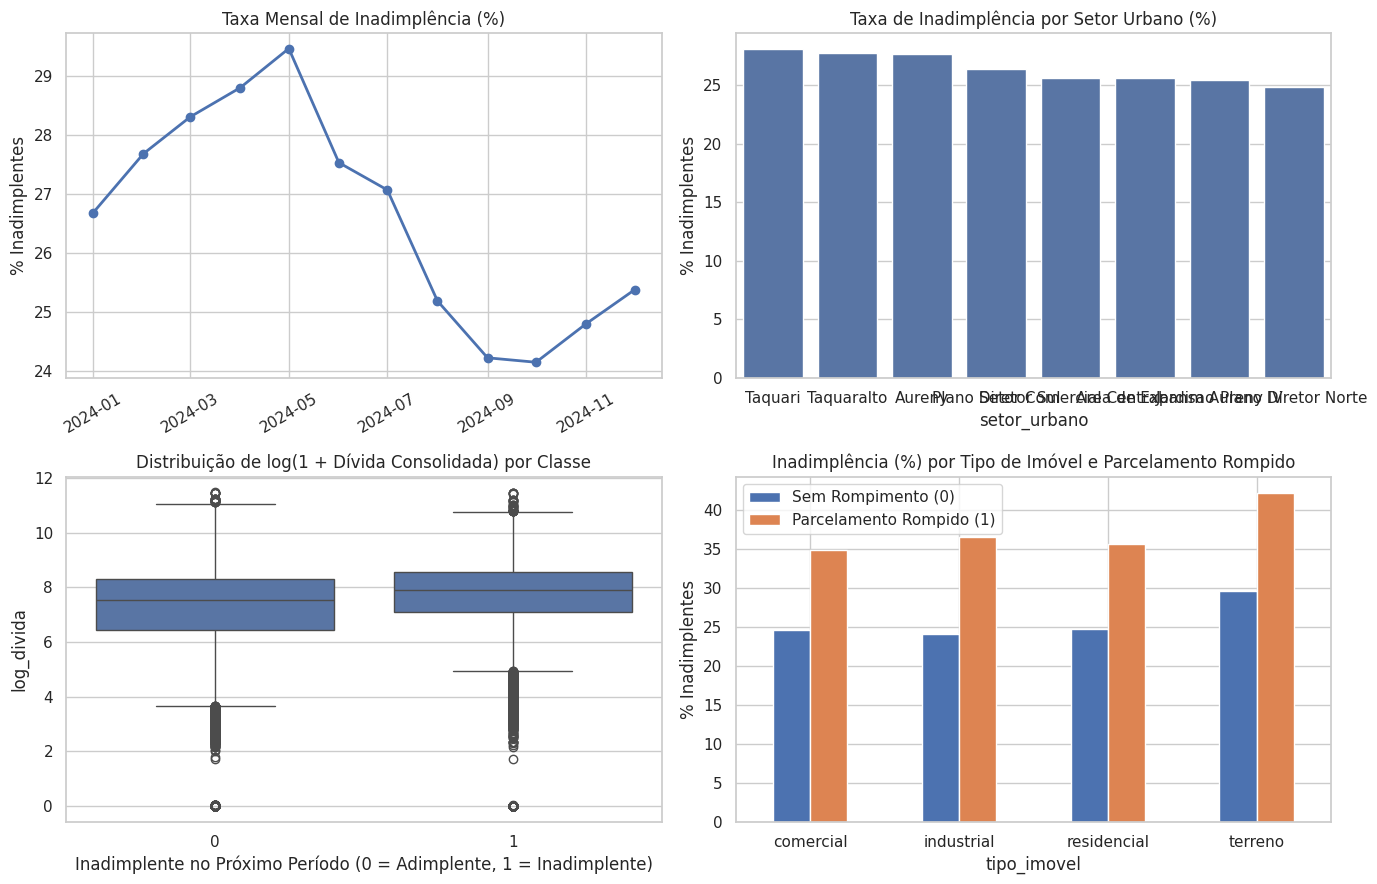

In [3]:
ALVO = 'inadimplente_proximo_periodo'
ATRIBUTOS = ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS

print(f'Dimensões da base: {df_historico.shape[0]:,} linhas x {df_historico.shape[1]} colunas')
print(f'Valores ausentes totais: {int(df_historico[ATRIBUTOS + [ALVO]].isna().sum().sum())}')
print(f'Taxa global de inadimplência (classe 1): {df_historico[ALVO].mean():.2%}')

display(df_historico[ATRIBUTOS_NUMERICOS].describe().T[['min', '25%', '50%', 'mean', '75%', 'max']].round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

serie_mensal = df_historico.groupby('data_referencia_simulada')[ALVO].mean() * 100
axes[0, 0].plot(serie_mensal.index, serie_mensal.values, marker='o', linewidth=2)
axes[0, 0].set_title('Taxa Mensal de Inadimplência (%)')
axes[0, 0].set_ylabel('% Inadimplentes')
axes[0, 0].tick_params(axis='x', rotation=30)

por_setor = df_historico.groupby('setor_urbano')[ALVO].mean().sort_values(ascending=False) * 100
sns.barplot(x=por_setor.index, y=por_setor.values, ax=axes[0, 1])
axes[0, 1].set_title('Taxa de Inadimplência por Setor Urbano (%)')
axes[0, 1].set_ylabel('% Inadimplentes')

df_plot = df_historico.copy()
df_plot['log_divida'] = np.log1p(df_plot['valor_divida_consolidada'])
sns.boxplot(data=df_plot, x=ALVO, y='log_divida', ax=axes[1, 0])
axes[1, 0].set_title('Distribuição de log(1 + Dívida Consolidada) por Classe')
axes[1, 0].set_xlabel('Inadimplente no Próximo Período (0 = Adimplente, 1 = Inadimplente)')

pivot_risco = df_historico.pivot_table(
    index='tipo_imovel', columns='parcelamento_rompido', values=ALVO, aggfunc='mean'
) * 100
pivot_risco.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Inadimplência (%) por Tipo de Imóvel e Parcelamento Rompido')
axes[1, 1].set_ylabel('% Inadimplentes')
axes[1, 1].tick_params(axis='x', rotation=0)
axes[1, 1].legend(['Sem Rompimento (0)', 'Parcelamento Rompido (1)'])

plt.tight_layout()
plt.show()

## 4. Split Temporal (60% / 20% / 20%) e Validação Anti-Vazamento

In [4]:
treino, validacao, teste = dividir_temporal(
    df_historico,
    coluna_data='data_referencia_simulada',
    proporcao_treino=0.60,
    proporcao_validacao=0.20,
)

assert treino['data_disponibilidade_alvo'].max() <= validacao['data_referencia_simulada'].min()
assert validacao['data_disponibilidade_alvo'].max() <= teste['data_referencia_simulada'].min()

X_treino, y_treino = treino[ATRIBUTOS], treino[ALVO]
X_validacao, y_validacao = validacao[ATRIBUTOS], validacao[ALVO]
X_teste, y_teste = teste[ATRIBUTOS], teste[ALVO]

for nome_part, part in [('Treino', treino), ('Validação', validacao), ('Teste', teste)]:
    d_ini = part['data_referencia_simulada'].min().strftime('%Y-%m-%d')
    d_fim = part['data_referencia_simulada'].max().strftime('%Y-%m-%d')
    print(f'{nome_part:10s} | {len(part):6,d} registros | {d_ini} a {d_fim} | Inadimplência: {part[ALVO].mean():.2%}')


Treino     | 130,249 registros | 2024-01-01 a 2024-07-01 | Inadimplência: 27.93%
Validação  | 37,214 registros | 2024-08-01 a 2024-09-01 | Inadimplência: 24.71%
Teste      | 55,821 registros | 2024-10-01 a 2024-12-01 | Inadimplência: 24.78%


## 5. Pré-processamento e Transformadores

In [5]:
def criar_preprocessador() -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ('numericas', StandardScaler(), ATRIBUTOS_NUMERICOS),
            ('categoricas', OneHotEncoder(handle_unknown='ignore'), ATRIBUTOS_CATEGORICOS),
        ],
        remainder='drop'
    )

preprocessador_auditado = criar_preprocessador()
X_treino_transf = preprocessador_auditado.fit_transform(X_treino)
print(f'Matriz transformada de treino: {X_treino_transf.shape[0]:,} amostras x {X_treino_transf.shape[1]} features')

Matriz transformada de treino: 130,249 amostras x 22 features


## 6. Treinamento de Baselines Temporais e Otimização de Limiar

In [6]:
def calcular_ks(y_true: np.ndarray, y_prob: np.ndarray) -> float:
    p1 = y_prob[y_true == 1]
    p0 = y_prob[y_true == 0]
    if len(p1) == 0 or len(p0) == 0:
        return 0.0
    return float(ks_2samp(p1, p0).statistic)

def selecionar_melhor_limiar(y_val: pd.Series, probs_val: np.ndarray) -> float:
    limites = np.round(np.arange(0.05, 0.55, 0.01), 2)
    scores = [f1_score(y_val, probs_val >= lim, zero_division=0) for lim in limites]
    return float(limites[int(np.argmax(scores))])

baselines_cfg = {
    'Regressao_Logistica_Temporal': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'Arvore_Decisao_Temporal': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
}

modelos_treinados = {}
historico_metricas = []

for nome, clf in baselines_cfg.items():
    pipe = Pipeline([('preparo', criar_preprocessador()), ('modelo', clf)])
    pipe.fit(X_treino, y_treino)
    modelos_treinados[nome] = pipe

    probs_val = pipe.predict_proba(X_validacao)[:, 1]
    probs_test = pipe.predict_proba(X_teste)[:, 1]
    limiar = selecionar_melhor_limiar(y_validacao, probs_val)
    preds_test = (probs_test >= limiar).astype(int)

    historico_metricas.append({
        'Modelo': nome,
        'Limiar_F1': limiar,
        'Acuracia_Teste': round(accuracy_score(y_teste, preds_test), 4),
        'Precisao_Teste': round(precision_score(y_teste, preds_test, zero_division=0), 4),
        'Recall_Teste': round(recall_score(y_teste, preds_test, zero_division=0), 4),
        'F1_Teste': round(f1_score(y_teste, preds_test, zero_division=0), 4),
        'ROC_AUC_Teste': round(roc_auc_score(y_teste, probs_test), 4),
        'KS_Teste': round(calcular_ks(y_teste.to_numpy(), probs_test), 4),
    })

pd.DataFrame(historico_metricas)

,Modelo,Limiar_F1,Acuracia_Teste,Precisao_Teste,Recall_Teste,F1_Teste,ROC_AUC_Teste,KS_Teste
0,Regressao_Logistica_Temporal,0.23,0.4960,0.2942,0.7391,0.4209,0.6167,0.1677
1,Arvore_Decisao_Temporal,0.23,0.4899,0.2918,0.7420,0.4189,0.6126,0.1637


## 7. Modelagem Avançada, Tunagem Temporal e Calibração de Probabilidades

In [7]:
def calibrar_modelo_prefit(estimador_treinado, X_cal, y_cal):
    try:
        from sklearn.frozen import FrozenEstimator
        calibrador = CalibratedClassifierCV(estimator=FrozenEstimator(estimador_treinado), method='sigmoid')
    except ImportError:
        calibrador = CalibratedClassifierCV(estimator=estimador_treinado, method='sigmoid', cv='prefit')
    calibrador.fit(X_cal, y_cal)
    return calibrador

X_tuning = pd.concat([X_treino, X_validacao], axis=0)
y_tuning = pd.concat([y_treino, y_validacao], axis=0)
split_index = np.concatenate([np.full(len(X_treino), -1), np.zeros(len(X_validacao))])
cv_temporal = PredefinedSplit(test_fold=split_index)

candidatos_avancados = {
    'RandomForest_Temporal_Tunado': {
        'estimador': RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1),
        'params': {
            'modelo__n_estimators': [150, 250, 350],
            'modelo__max_depth': [6, 10, 14],
            'modelo__min_samples_split': [5, 10, 20],
            'modelo__min_samples_leaf': [2, 5, 10],
        },
    },
    'GradientBoosting_Temporal_Tunado': {
        'estimador': GradientBoostingClassifier(random_state=RANDOM_STATE),
        'params': {
            'modelo__n_estimators': [150, 250, 350],
            'modelo__learning_rate': [0.03, 0.05, 0.1],
            'modelo__max_depth': [3, 4, 6],
            'modelo__subsample': [0.8, 1.0],
        },
    },
}

melhores_hiperparametros = {}

for nome, cfg in candidatos_avancados.items():
    pipe = Pipeline([('preparo', criar_preprocessador()), ('modelo', cfg['estimador'])])
    busca = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=cfg['params'],
        n_iter=10,
        scoring='roc_auc',
        cv=cv_temporal,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    busca.fit(X_tuning, y_tuning)
    melhores_hiperparametros[nome] = busca.best_params_

    melhor_pipe = busca.best_estimator_
    melhor_pipe.fit(X_treino, y_treino)

    modelo_calibrado = calibrar_modelo_prefit(melhor_pipe, X_validacao, y_validacao)
    modelos_treinados[nome] = modelo_calibrado

    probs_val = modelo_calibrado.predict_proba(X_validacao)[:, 1]
    probs_test = modelo_calibrado.predict_proba(X_teste)[:, 1]
    limiar = selecionar_melhor_limiar(y_validacao, probs_val)
    preds_test = (probs_test >= limiar).astype(int)

    historico_metricas.append({
        'Modelo': nome,
        'Limiar_F1': limiar,
        'Acuracia_Teste': round(accuracy_score(y_teste, preds_test), 4),
        'Precisao_Teste': round(precision_score(y_teste, preds_test, zero_division=0), 4),
        'Recall_Teste': round(recall_score(y_teste, preds_test, zero_division=0), 4),
        'F1_Teste': round(f1_score(y_teste, preds_test, zero_division=0), 4),
        'ROC_AUC_Teste': round(roc_auc_score(y_teste, probs_test), 4),
        'KS_Teste': round(calcular_ks(y_teste.to_numpy(), probs_test), 4),
    })

df_comparativo = pd.DataFrame(historico_metricas).sort_values(by='ROC_AUC_Teste', ascending=False).reset_index(drop=True)
display(df_comparativo)

,Modelo,Limiar_F1,Acuracia_Teste,Precisao_Teste,Recall_Teste,F1_Teste,ROC_AUC_Teste,KS_Teste
0,Regressao_Logistica_Temporal,0.23,0.4960,0.2942,0.7391,0.4209,0.6167,0.1677
1,GradientBoosting_Temporal_Tunado,0.21,0.5024,0.2962,0.7329,0.4219,0.6157,0.1663
2,RandomForest_Temporal_Tunado,0.23,0.5103,0.2976,0.7177,0.4207,0.6154,0.1682
3,Arvore_Decisao_Temporal,0.23,0.4899,0.2918,0.7420,0.4189,0.6126,0.1637


## 8. Avaliação Comparativa e Diagnóstico Visual do Modelo Campeão

Modelo Campeão Selecionado: Regressao_Logistica_Temporal (Limiar F1: 0.23)


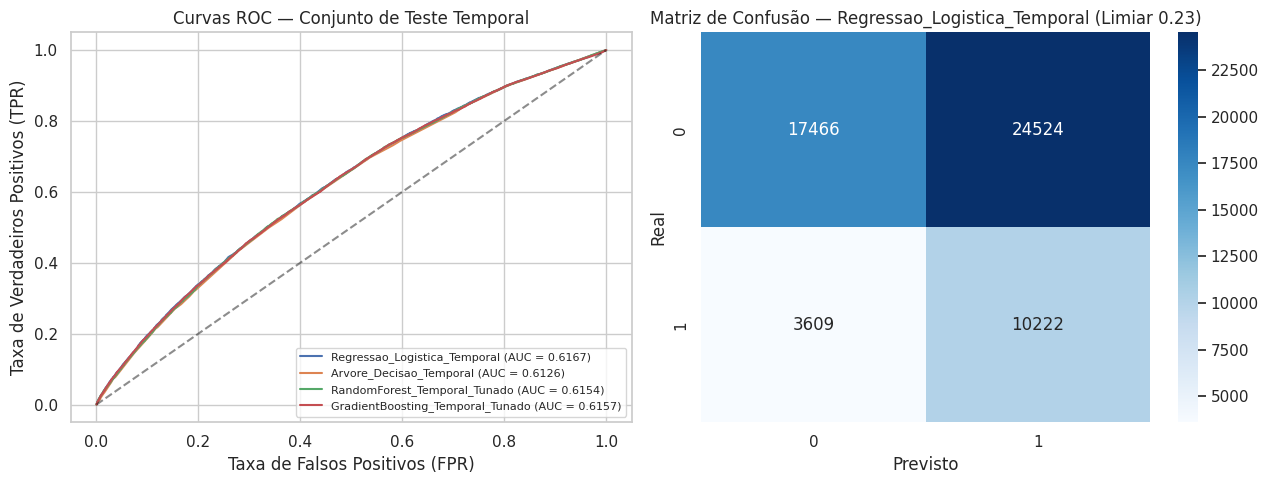

              precision    recall  f1-score   support

           0     0.8288    0.4160    0.5539     41990
           1     0.2942    0.7391    0.4209     13831

    accuracy                         0.4960     55821
   macro avg     0.5615    0.5775    0.4874     55821
weighted avg     0.6963    0.4960    0.5209     55821



In [8]:
nome_campeao = df_comparativo.iloc[0]['Modelo']
limiar_campeao = float(df_comparativo.iloc[0]['Limiar_F1'])
modelo_campeao = modelos_treinados[nome_campeao]

print(f'Modelo Campeão Selecionado: {nome_campeao} (Limiar F1: {limiar_campeao})')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for nome, mod in modelos_treinados.items():
    probs = mod.predict_proba(X_teste)[:, 1]
    fpr, tpr, _ = roc_curve(y_teste, probs)
    auc_val = roc_auc_score(y_teste, probs)
    axes[0].plot(fpr, tpr, label=f'{nome} (AUC = {auc_val:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Curvas ROC — Conjunto de Teste Temporal')
axes[0].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
axes[0].legend(loc='lower right', fontsize=8)

probs_camp = modelo_campeao.predict_proba(X_teste)[:, 1]
preds_camp = (probs_camp >= limiar_campeao).astype(int)
cm = confusion_matrix(y_teste, preds_camp)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title(f'Matriz de Confusão — {nome_campeao} (Limiar {limiar_campeao})')
axes[1].set_xlabel('Previsto')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

print(classification_report(y_teste, preds_camp, digits=4))

## 9. Serialização dos Artefatos (`joblib`) e Validação de Inferência

In [9]:
caminho_campeao = PASTA_MODELS / 'modelo_campeao_recuperabilidade.joblib'
caminho_preproc = PASTA_MODELS / 'preprocessador_inadimplencia.joblib'
caminho_metadados = PASTA_MODELS / 'metadados_modelo_campeao.json'

joblib.dump(modelo_campeao, caminho_campeao, compress=3)
joblib.dump(preprocessador_auditado, caminho_preproc, compress=3)
joblib.dump(modelos_treinados['Regressao_Logistica_Temporal'], PASTA_MODELS / 'regressao_logistica_temporal.joblib', compress=3)
joblib.dump(modelos_treinados['Arvore_Decisao_Temporal'], PASTA_MODELS / 'arvore_decisao_temporal.joblib', compress=3)

sha256_modelo = hashlib.sha256(caminho_campeao.read_bytes()).hexdigest()

metadados = {
    'modelo_campeao': nome_campeao,
    'gerado_em_utc': datetime.now(timezone.utc).isoformat(),
    'random_state': RANDOM_STATE,
    'limiar_decisao_f1': limiar_campeao,
    'atributos_numericos': ATRIBUTOS_NUMERICOS,
    'atributos_categoricos': ATRIBUTOS_CATEGORICOS,
    'alvo': ALVO,
    'hiperparametros': melhores_hiperparametros.get(nome_campeao, {}),
    'metricas_teste': df_comparativo.iloc[0].to_dict(),
    'sha256_modelo_campeao': sha256_modelo,
}

caminho_metadados.write_text(json.dumps(metadados, indent=2, ensure_ascii=False), encoding='utf-8')

amostra_escorada = gerar_scoring_recuperabilidade(teste.head(10), caminho_modelo=str(caminho_campeao))
print(f'Artefato salvo com sucesso: {caminho_campeao} (SHA-256: {sha256_modelo[:16]}...)')
display(amostra_escorada[['valor_divida_consolidada', 'prob_inadimplencia', 'score_recuperabilidade', 'faixa_recuperabilidade']].head())

Artefato salvo com sucesso: /workspaces/inteligencia_tributaria/models/modelo_campeao_recuperabilidade.joblib (SHA-256: d5bbce7d35baca13...)


,valor_divida_consolidada,prob_inadimplencia,score_recuperabilidade,faixa_recuperabilidade
167464,7559.07,0.2810,719,Faixa B - Média Recuperabilidade
167468,5891.49,0.3450,655,Faixa B - Média Recuperabilidade
167470,4795.95,0.4061,594,Faixa B - Média Recuperabilidade
167469,2447.37,0.3551,645,Faixa B - Média Recuperabilidade
167471,1869.07,0.3337,666,Faixa B - Média Recuperabilidade
